# UK Contracts for Difference | Renewable Generation & Financial Analytics

**Portfolio study · June 2016–September 2026 historical data, plus forward-looking snapshots**

The UK's Contracts for Difference (CfD) scheme is designed to support low-carbon electricity projects. This notebook looks at the actual generation and payments associated with CfD units, the contract portfolio, auction awards, and the forward-looking price and payment information published by LCCC.

My objective is to understand three things: **where generation is coming from**, **how financial flows change with market conditions**, and **what the contract pipeline says about the future energy mix**. Along the way I want to turn the raw data into a practical dataset that can be used in Tableau.

### Questions I want to answer

1. How has CfD-supported generation changed over time, and which technologies account for most of it?
2. When are payments to generators positive or negative, and how does that relate to reference prices?
3. How much estimated GHG avoidance is associated with supported generation?
4. How do the current contract portfolio and auction outcomes differ by technology?
5. What can the **available forecasts** tell us about near-term payment expectations and prices?

**Source:** LCCC Data Portal — <https://dp.lowcarboncontracts.uk/>. All six input files are downloaded CSV snapshots. Data dates and source definitions should be re-checked before external publication.

## 1. Environment and file layout

The notebook runs from the project root, or from `notebooks/` inside the same project. Source data should be stored in `data/raw/`; the Tableau export is written to `data/processed/`. I use pandas for data preparation and matplotlib/seaborn for the charts. Figures are left in the notebook output so the analysis can be reviewed without re-running it.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 24)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.03)
plt.rcParams.update({"figure.figsize": (11.5, 5.4), "axes.titleweight": "semibold", "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"teal": "#147D75", "navy": "#193C57", "gold": "#D6A047", "coral": "#D36854", "slate": "#63798B"}

HERE = Path.cwd().resolve()
PROJECT = HERE if (HERE / "data" / "raw").is_dir() else HERE.parent
RAW = PROJECT / "data" / "raw"
OUT = PROJECT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
FILES = {
    "actual": "actual_cfd_generation_and_avoided_ghg_emissions.csv",
    "portfolio": "cfd_contract_portfolio_status.csv",
    "auctions": "auction_outcomes.csv",
    "annual_forecast": "forecast_average_strike_price_and_market_price.csv",
    "market_forecast": "forecast_market_reference_prices.csv",
    "tracking": "in_period_tracking.csv",
}
missing = [name for name in FILES.values() if not (RAW / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing CSVs in {RAW}: {missing}")
print("Project folder:", PROJECT)
print("Input folder:", RAW)
print("Output folder:", OUT)

Project folder: /mnt/data/UK_CfD_Analytics_Project
Input folder: /mnt/data/UK_CfD_Analytics_Project/data/raw
Output folder: /mnt/data/UK_CfD_Analytics_Project/data/processed


## 2. Read the datasets and check their structure

Each source represents a different kind of observation. Historical generation is recorded at **CfD unit/day** level, portfolio information at **contract** level, auction outcomes at **award** level, and the forward-looking sources at their own forecast horizons. I do not merge these tables row-for-row: joining records at different grains would multiply the payment or generation values.

In [2]:
tables = {key: pd.read_csv(RAW / filename, low_memory=False) for key, filename in FILES.items()}
inventory = pd.DataFrame([
    {"Dataset": key, "Rows": len(df), "Columns": df.shape[1], "Duplicate rows": int(df.duplicated().sum()),
     "Missing cells": int(df.isna().sum().sum())}
    for key, df in tables.items()
]).set_index("Dataset")
display(inventory)
for label, frame in tables.items():
    print(f"{label}: {', '.join(frame.columns)}")

,Rows,Columns,Duplicate rows,Missing cells
Dataset,,,,
actual,117877,13,0,4278
portfolio,610,8,0,45
auctions,570,11,0,549
annual_forecast,323,10,0,1439
market_forecast,2505,4,0,0
tracking,457,13,0,3294


actual: Settlement_Date, CfD_ID, Name_of_CfD_Unit, Technology, Allocation_round, Reference_Type, CFD_Generation_MWh, Avoided_GHG_tonnes_CO2e, CFD_Payments_GBP, Avoided_GHG_Cost_GBP, Strike_Price_GBP_Per_MWh, Market_Reference_Price_GBP_Per_MWh, Weighted_IMRP_GBP_Per_MWh
portfolio: CFD_ID, Name_of_CFD_Unit, Allocation_Round, Technology_Type, Transmission_or_Distribution_connection, Status, Expected_Start_Date, Maximum_Contract_Capacity_MW
auctions: Auction, Version, Publication_Date, Project_Name, Developer, Technology_Type, Capacity_MW, Strike_Price_GBP_Per_MWh, Delivery_Year, Homes_Powered, Region
annual_forecast: Financial_Year, Technology_type, Transmission_or_Distribution_connection, Allocation_Round_1_Weighted_Average_Strike_Price_GBP_per_MWh, Allocation_Round_2_Weighted_Average_Strike_Price_GBP_per_MWh, Allocation_Round_3_Weighted_Average_Strike_Price_GBP_per_MWh, Bespoke_Weighted_Average_Strike_Price_GBP_per_MWh, Investment_Contract_Weighted_Average_Strike_Price_GBP_per_MWh, Weig

### Data preparation

I standardise the date fields, trim text labels and remove only **exact** duplicate rows. Zeros and negative payments are preserved because they can be economically meaningful. I do not fill missing actual figures with zeros: a missing observation and an observed zero are not the same thing.

In [3]:
actual = tables["actual"].drop_duplicates().copy()
portfolio = tables["portfolio"].drop_duplicates().copy()
auctions = tables["auctions"].drop_duplicates().copy()
annual = tables["annual_forecast"].drop_duplicates().copy()
market = tables["market_forecast"].drop_duplicates().copy()
tracking = tables["tracking"].drop_duplicates().copy()

for frame in [actual, portfolio, auctions, annual, market, tracking]:
    for col in frame.select_dtypes(include="object"):
        frame[col] = frame[col].str.strip()

for frame, columns in [(actual, ["Settlement_Date"]), (portfolio, ["Expected_Start_Date"]),
                       (auctions, ["Publication_Date"]), (market, ["DateTime"]), (tracking, ["Settlement_Date"])]:
    for col in columns:
        frame[col] = pd.to_datetime(frame[col], errors="coerce")

actual["Month"] = actual["Settlement_Date"].dt.to_period("M").dt.to_timestamp()
actual["Year"] = actual["Settlement_Date"].dt.year
actual["Generation_x_Strike"] = actual["CFD_Generation_MWh"] * actual["Strike_Price_GBP_Per_MWh"]
actual["Generation_x_Market"] = actual["CFD_Generation_MWh"] * actual["Market_Reference_Price_GBP_Per_MWh"]

print("Actual data range:", actual["Settlement_Date"].min().date(), "to", actual["Settlement_Date"].max().date())
print("Portfolio contracts:", portfolio["CFD_ID"].nunique())
print("Auction rounds:", ", ".join(sorted(auctions["Auction"].unique())))
print("Tracking actual CfD payments available:", tracking["Actual_CFD_Payments_GBP"].notna().sum(), "of", len(tracking))
assert not actual.duplicated(["Settlement_Date", "CfD_ID"]).any(), "Duplicate unit/day observations need investigation"
assert not portfolio["CFD_ID"].duplicated().any(), "Portfolio contract IDs need investigation"
assert (actual["CFD_Generation_MWh"] >= 0).all(), "Unexpected negative generation"

Actual data range: 2016-06-30 to 2026-09-30
Portfolio contracts: 610
Auction rounds: AR1, AR2, AR3, AR4, AR5, AR6, AR7
Tracking actual CfD payments available: 0 of 457


## 3. Data quality and coverage

Before analysing performance, I want to see how complete each column is. Missing values are not spread equally across the sources. In particular, the in-period tracking download contains forecast values but **no populated actual payment observations**. That means I can discuss forecast revisions, but I cannot estimate actual-versus-forecast accuracy from this file.

,dataset,column,missing_pct
0,tracking,Initial_Forecast_LCDCFD_Payments_GBP,100.00
1,tracking,Actual_CFD_Payments_GBP,100.00
2,tracking,Actual_Eligible_Demand_MWh,100.00
3,tracking,Actual_Supplier_Payments_GBP,100.00
4,tracking,Actual_LCDCFD_Payments_GBP,100.00
5,annual_forecast,Bespoke_Weighted_Average_Strike_Price_GBP_per_MWh,96.28
6,auctions,Homes_Powered,95.96
7,annual_forecast,Allocation_Round_2_Weighted_Average_Strike_Pri...,94.74
8,annual_forecast,Allocation_Round_3_Weighted_Average_Strike_Pri...,86.69
9,annual_forecast,Investment_Contract_Weighted_Average_Strike_Pr...,81.42


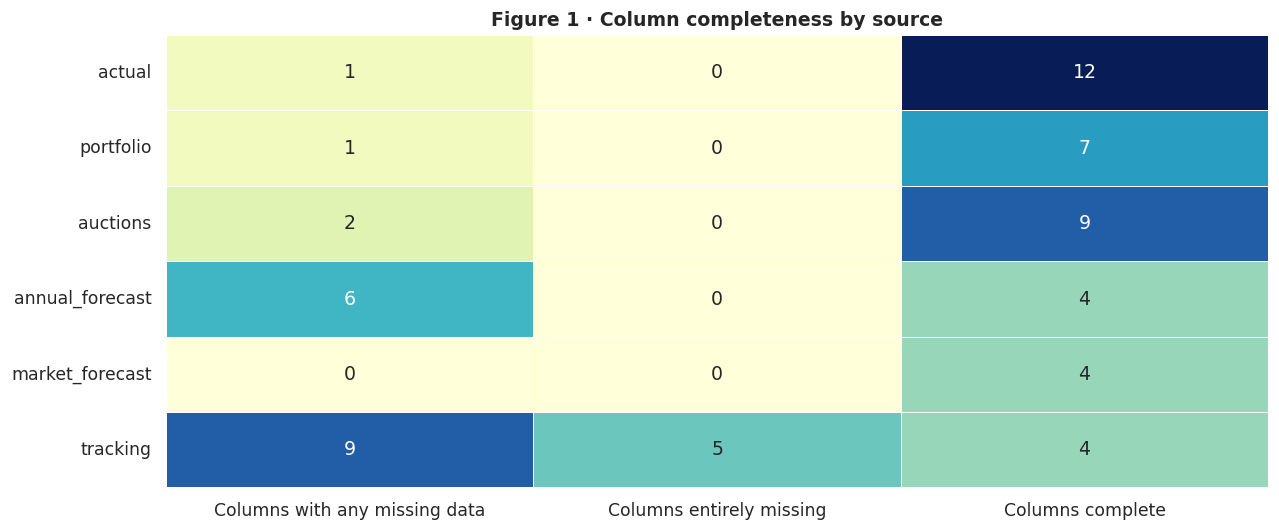

In [4]:
quality = pd.concat([
    pd.DataFrame({"dataset": key, "column": df.columns, "missing_pct": (df.isna().mean().values * 100)})
    for key, df in tables.items()
], ignore_index=True)
quality_sorted = quality.sort_values("missing_pct", ascending=False)
display(quality_sorted.head(16).reset_index(drop=True))

# Figure 1: missingness overview by dataset
missing_matrix = pd.DataFrame({key: {"Columns with any missing data": int(df.isna().any().sum()),
                                     "Columns entirely missing": int(df.isna().all().sum()),
                                     "Columns complete": int(df.notna().all().sum())}
                               for key, df in tables.items()}).T
fig, ax = plt.subplots(figsize=(11.8, 5.0))
sns.heatmap(missing_matrix, annot=True, fmt="d", cmap="YlGnBu", linewidths=.6, ax=ax, cbar=False)
ax.set(title="Figure 1 · Column completeness by source", xlabel="", ylabel="")
plt.xticks(rotation=0); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

**Reading the quality check:** the large number of empty fields in the tracking dataset reflects data availability, not a cleaning failure. The sparse `Homes_Powered` field in the auctions dataset is also not suitable for cross-auction comparisons without further context. The historical dataset retains zero-generation settlement days; these are valid observations rather than missing data.

## 4. Historical generation and CfD payments

For the first group of charts I use only the historic settlement records. Energy is measured in **MWh**, payments in **GBP**, and avoided emissions in **tonnes CO₂e**. CfD payments can be negative when the relevant market reference price exceeds the contract strike price; I keep the signed amounts instead of using absolute values.

In [5]:
yearly = actual.groupby("Year", as_index=False).agg(
    Generation_MWh=("CFD_Generation_MWh", "sum"),
    Payments_GBP=("CFD_Payments_GBP", "sum"),
    Avoided_tCO2e=("Avoided_GHG_tonnes_CO2e", "sum"))
tech_total = actual.groupby("Technology", as_index=False).agg(
    Generation_MWh=("CFD_Generation_MWh", "sum"),
    Payments_GBP=("CFD_Payments_GBP", "sum"),
    Avoided_tCO2e=("Avoided_GHG_tonnes_CO2e", "sum")).sort_values("Generation_MWh", ascending=False)
monthly_tech = actual.groupby(["Month", "Technology"], as_index=False).agg(
    Generation_MWh=("CFD_Generation_MWh", "sum"), Payments_GBP=("CFD_Payments_GBP", "sum"),
    Avoided_tCO2e=("Avoided_GHG_tonnes_CO2e", "sum"),
    Gen_x_Strike=("Generation_x_Strike", "sum"), Gen_x_Market=("Generation_x_Market", "sum"))
monthly_tech["Gen_weighted_strike"] = monthly_tech["Gen_x_Strike"] / monthly_tech["Generation_MWh"].replace(0, np.nan)
monthly_tech["Gen_weighted_reference"] = monthly_tech["Gen_x_Market"] / monthly_tech["Generation_MWh"].replace(0, np.nan)

print(f"Total recorded generation: {actual['CFD_Generation_MWh'].sum()/1e6:,.2f} million MWh")
print(f"Total net CfD payments: £{actual['CFD_Payments_GBP'].sum()/1e9:,.2f} billion")
print(f"Estimated avoided GHG emissions: {actual['Avoided_GHG_tonnes_CO2e'].sum()/1e6:,.2f} million tCO₂e")
display(tech_total)

Total recorded generation: 211.54 million MWh
Total net CfD payments: £13.84 billion
Estimated avoided GHG emissions: 31.31 million tCO₂e


,Technology,Generation_MWh,Payments_GBP,Avoided_tCO2e
4,Offshore Wind,"139,854,766.11","10,313,109,072.57","18,929,346.36"
1,Biomass Conversion,"54,384,818.15","3,021,722,172.10","10,156,867.62"
5,Onshore Wind,"11,466,148.42","223,089,441.78","1,575,434.31"
2,Dedicated Biomass,"3,508,520.24","314,742,939.86","371,154.16"
6,Solar PV,"1,540,441.16","-21,594,452.64","181,740.23"
3,Energy from Waste,"788,064.64","-9,173,904.82","92,702.55"
0,Advanced Conversion Technology,0.00,0.00,0.00


### Generation over time

First I look at annual totals, then break the monthly series down by technology. The first and final calendar years are partial coverage periods, so I will avoid interpreting their lower annual totals as year-on-year falls.

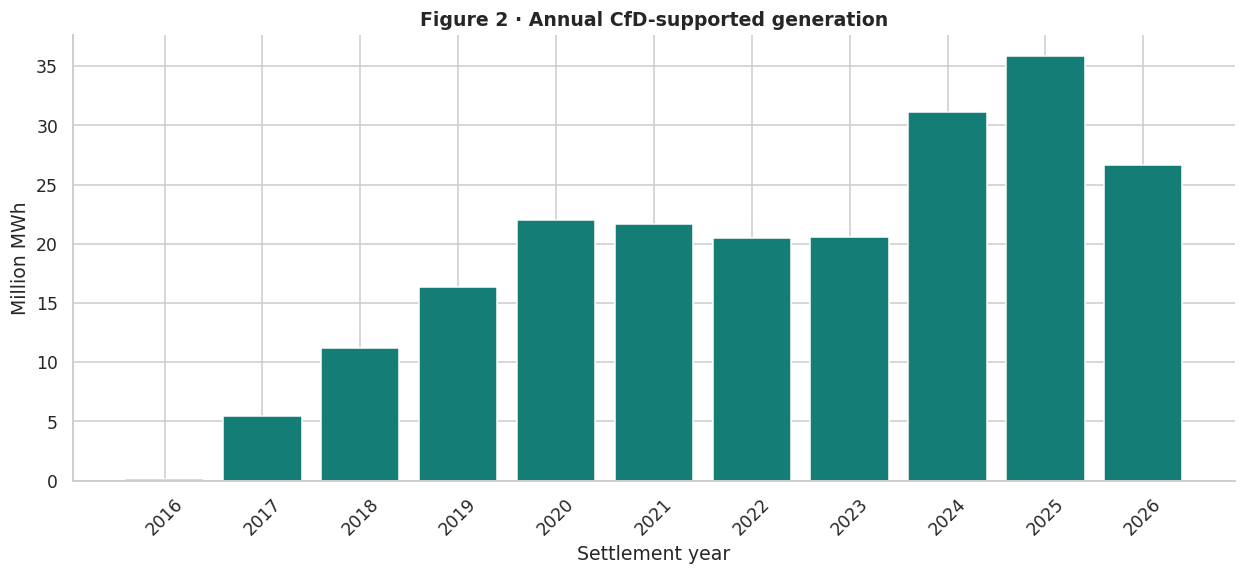

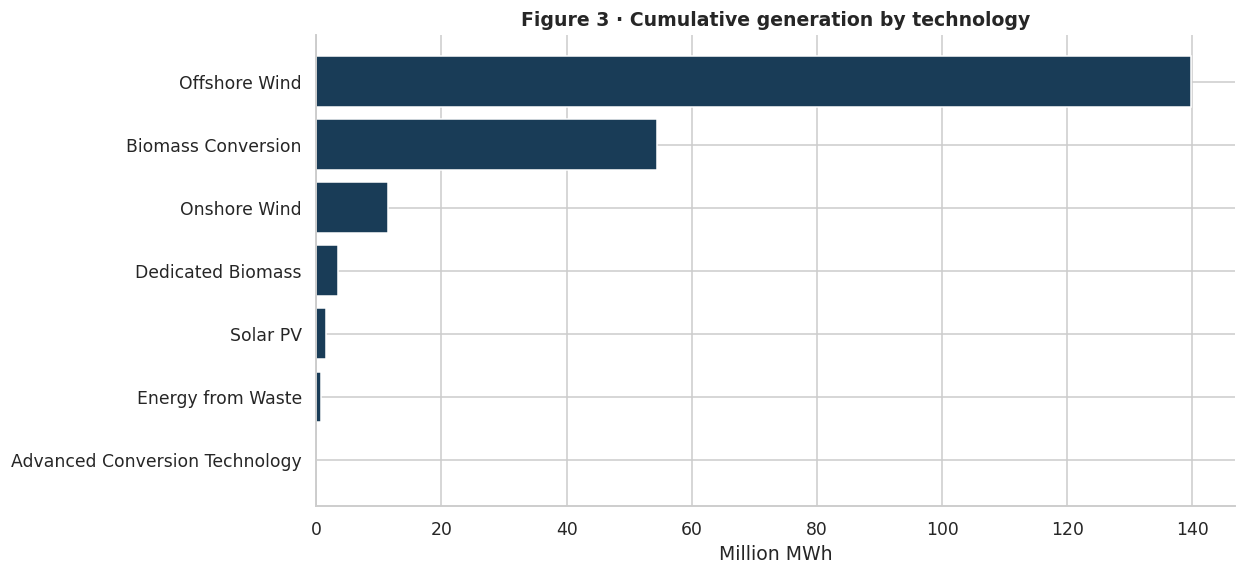

In [6]:
# Figure 2: annual generation
fig, ax = plt.subplots()
ax.bar(yearly["Year"].astype(str), yearly["Generation_MWh"] / 1e6, color=COLORS["teal"])
ax.set(title="Figure 2 · Annual CfD-supported generation", ylabel="Million MWh", xlabel="Settlement year")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# Figure 3: generation by technology
fig, ax = plt.subplots()
temp = tech_total.sort_values("Generation_MWh")
ax.barh(temp["Technology"], temp["Generation_MWh"] / 1e6, color=COLORS["navy"])
ax.set(title="Figure 3 · Cumulative generation by technology", xlabel="Million MWh", ylabel="")
plt.tight_layout(); plt.show()

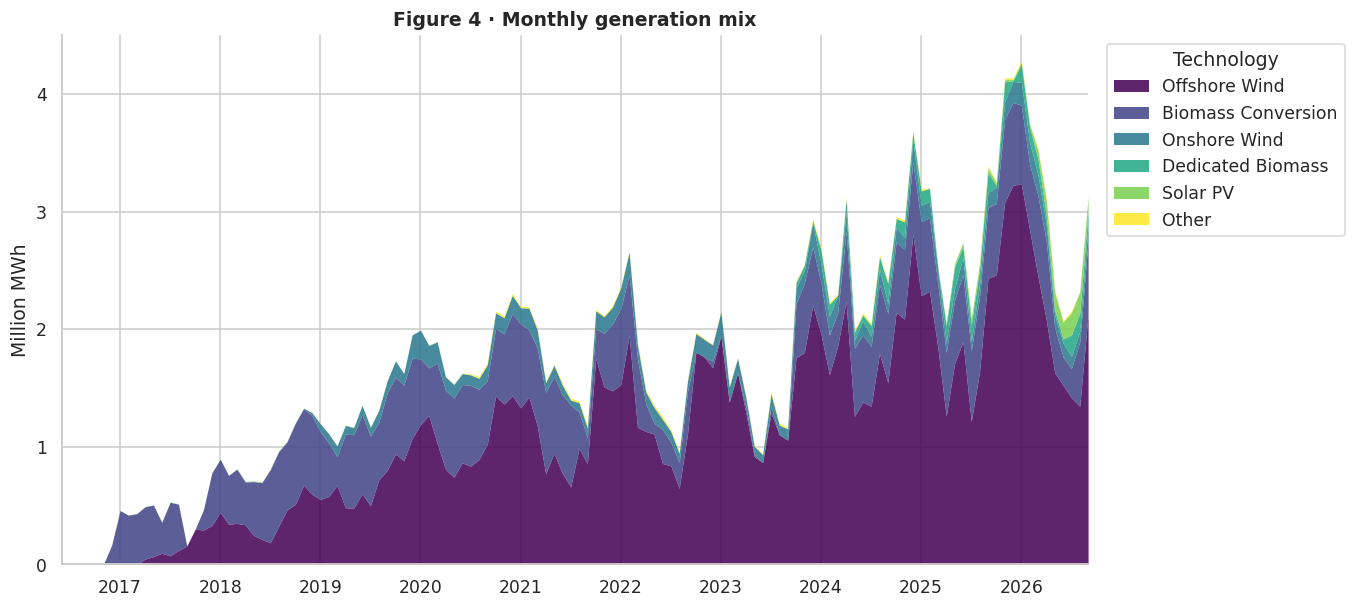

In [7]:
# Figure 4: monthly stacked generation, leading technologies plus Other
pivot = monthly_tech.pivot(index="Month", columns="Technology", values="Generation_MWh").fillna(0) / 1e6
major = pivot.sum().nlargest(5).index.tolist()
plot_gen = pivot[major].copy()
if len(pivot.columns) > len(major):
    plot_gen["Other"] = pivot.drop(columns=major).sum(axis=1)
fig, ax = plt.subplots(figsize=(12.5, 5.7))
plot_gen.plot.area(ax=ax, alpha=.86, linewidth=0, colormap="viridis")
ax.set(title="Figure 4 · Monthly generation mix", ylabel="Million MWh", xlabel="")
ax.legend(title="Technology", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation:** these plots show realised CfD-eligible generation from projects represented in the source, not total UK renewable output. The changing mix can reflect both new projects entering the scheme and changes in generation from existing units. Without plant-level weather and outage information, I should not attribute month-to-month movements to a single cause.

### Payments, market prices and the settlement mechanism

I next look at the net payments rather than grossing up all flows. For price comparisons I calculate a **generation-weighted mean** for each period; a simple average of unit-day prices would give very small and very large generators equal influence.

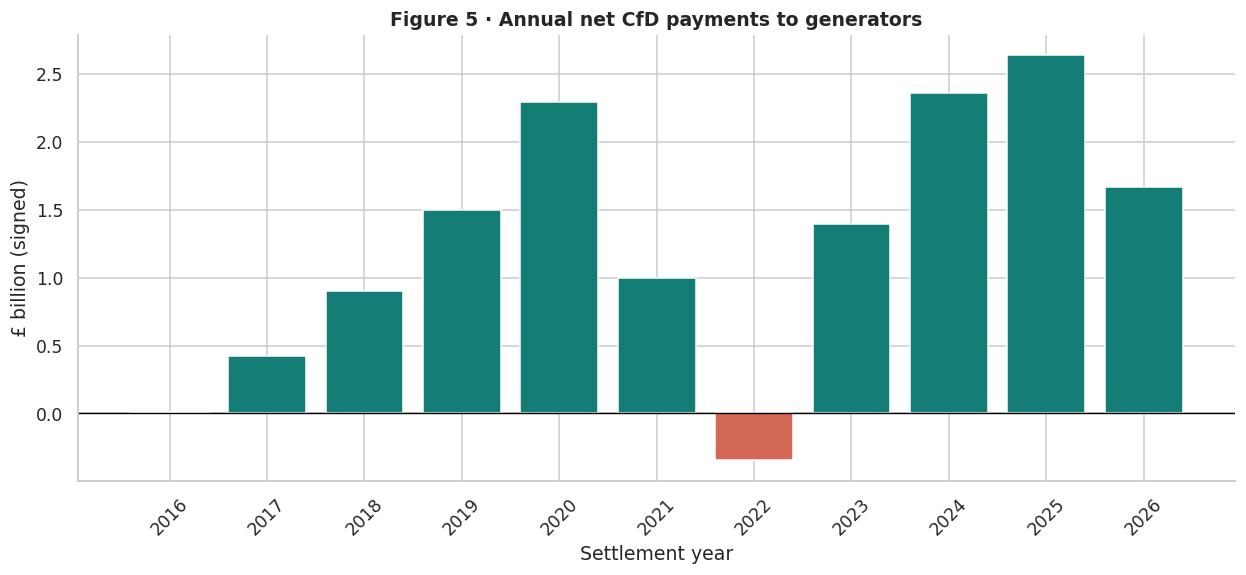

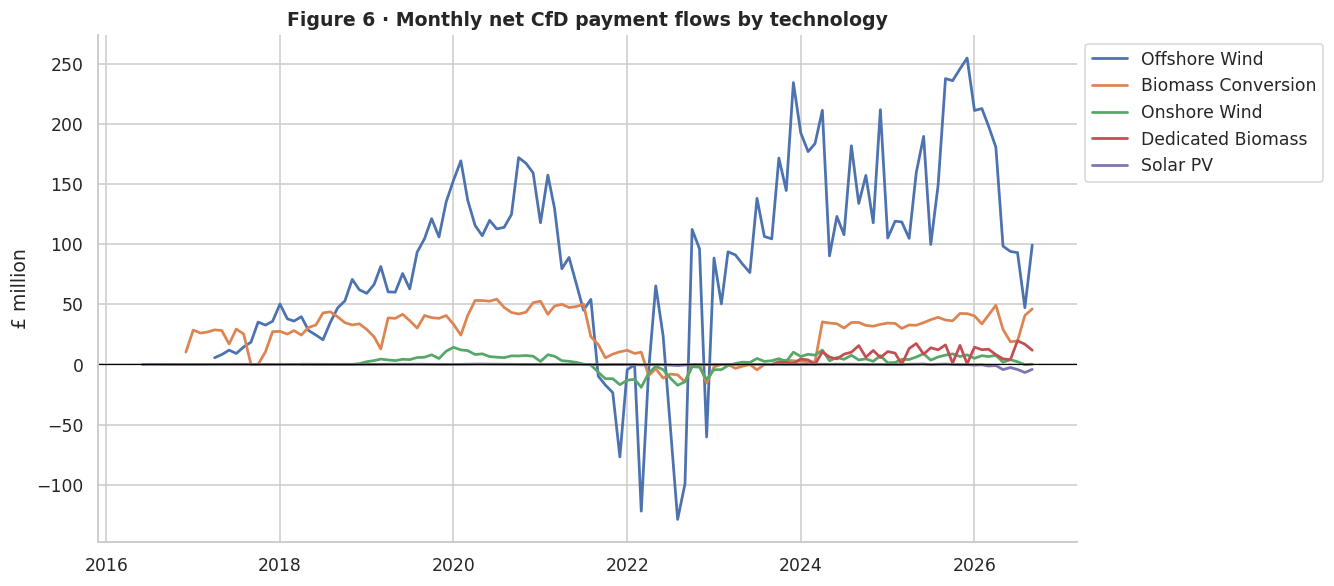

In [8]:
# Figure 5: signed annual CfD payments
fig, ax = plt.subplots()
heights = yearly["Payments_GBP"] / 1e9
ax.bar(yearly["Year"].astype(str), heights, color=[COLORS["teal"] if v >= 0 else COLORS["coral"] for v in heights])
ax.axhline(0, color="black", linewidth=.9)
ax.set(title="Figure 5 · Annual net CfD payments to generators", ylabel="£ billion (signed)", xlabel="Settlement year")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# Figure 6: monthly net payments by major technology
selected = tech_total["Technology"].head(5).tolist()
fig, ax = plt.subplots(figsize=(12.3, 5.5))
for name in selected:
    subset = monthly_tech[monthly_tech["Technology"] == name].sort_values("Month")
    ax.plot(subset["Month"], subset["Payments_GBP"] / 1e6, label=name, linewidth=1.8)
ax.axhline(0, color="black", linewidth=.8)
ax.set(title="Figure 6 · Monthly net CfD payment flows by technology", ylabel="£ million", xlabel="")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

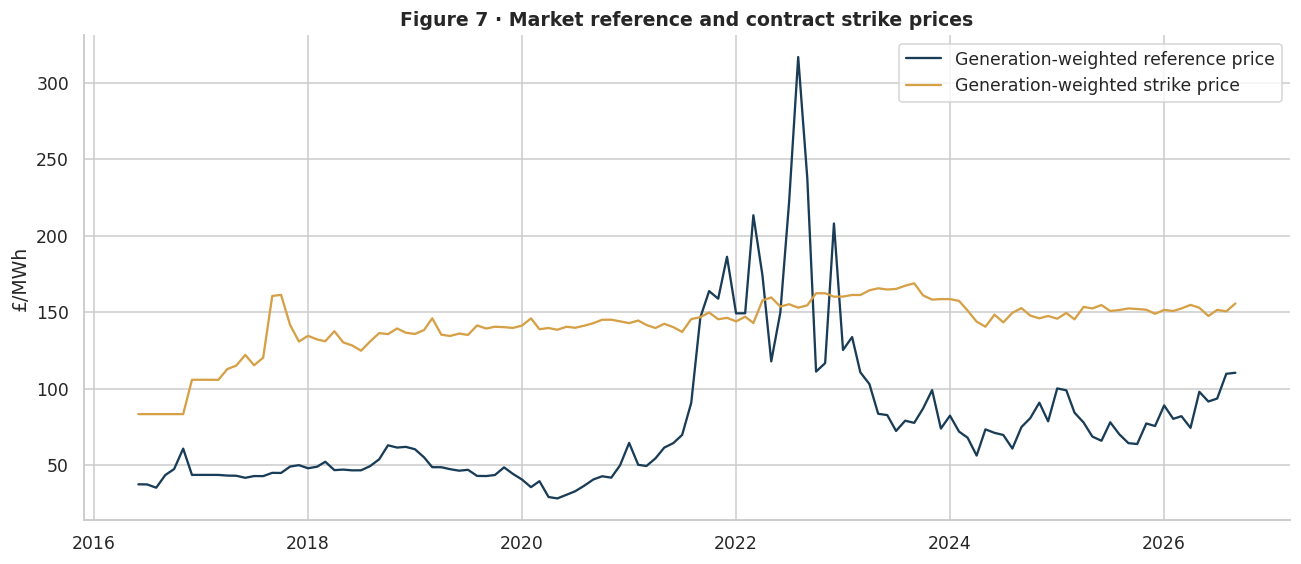

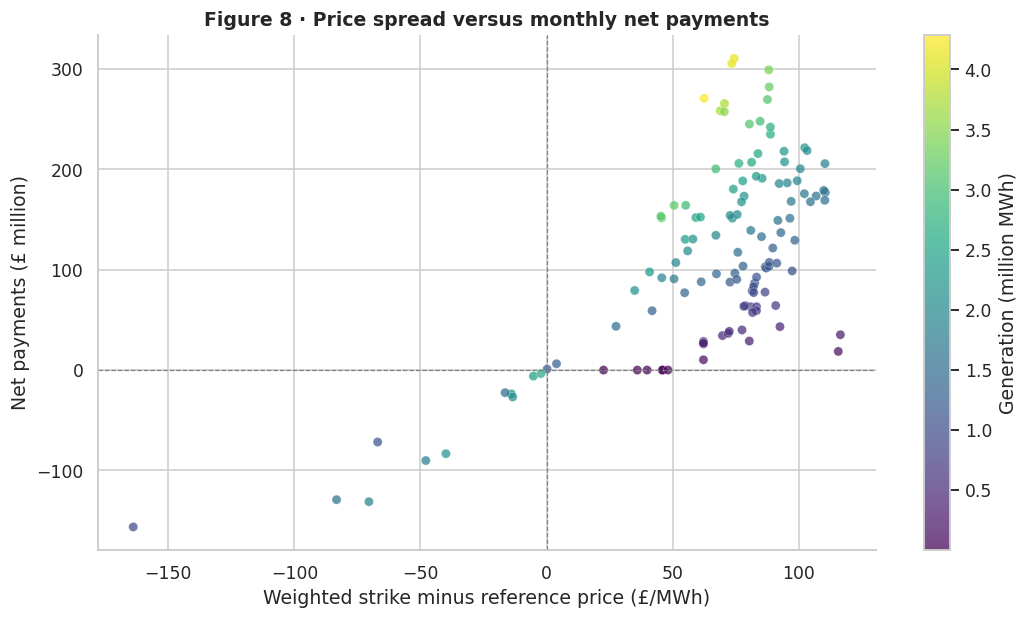

In [9]:
# Figure 7: monthly weighted price versus payments; aggregate source-wide to avoid duplicate-day weights
month_prices = actual.groupby("Month", as_index=False).agg(
    generation=("CFD_Generation_MWh", "sum"),
    price_weighted=("Generation_x_Market", "sum"),
    strike_weighted=("Generation_x_Strike", "sum"),
    payments=("CFD_Payments_GBP", "sum"))
month_prices = month_prices[month_prices["generation"] > 0].copy()
month_prices["reference_price"] = month_prices["price_weighted"] / month_prices["generation"]
month_prices["strike_price"] = month_prices["strike_weighted"] / month_prices["generation"]
fig, ax = plt.subplots(figsize=(12, 5.3))
ax.plot(month_prices["Month"], month_prices["reference_price"], label="Generation-weighted reference price", color=COLORS["navy"])
ax.plot(month_prices["Month"], month_prices["strike_price"], label="Generation-weighted strike price", color=COLORS["gold"])
ax.set(title="Figure 7 · Market reference and contract strike prices", xlabel="", ylabel="£/MWh")
ax.legend(); plt.tight_layout(); plt.show()

# Figure 8: observed price spread and signed payments
month_prices["spread"] = month_prices["strike_price"] - month_prices["reference_price"]
fig, ax = plt.subplots(figsize=(10, 5.8))
sc = ax.scatter(month_prices["spread"], month_prices["payments"] / 1e6,
                c=month_prices["generation"] / 1e6, cmap="viridis", alpha=.72, edgecolor="white", linewidth=.25)
ax.axhline(0, color="gray", linestyle="--", linewidth=.8); ax.axvline(0, color="gray", linestyle="--", linewidth=.8)
ax.set(title="Figure 8 · Price spread versus monthly net payments", xlabel="Weighted strike minus reference price (£/MWh)", ylabel="Net payments (£ million)")
plt.colorbar(sc, label="Generation (million MWh)", ax=ax)
plt.tight_layout(); plt.show()

**Interpretation:** the price spread and payments are associated by design, but the scatter plot is not a causal estimate. Payments depend on contract terms, eligible generation, applicable reference prices and settlement adjustments. A negative CfD payment is a valid outcome and should not be labelled a loss without defining whose perspective is being used.

### Estimated carbon impact and projects

The avoided emissions data is an estimate supplied in the source. I report its relationship to eligible generation, but I do **not** treat it as a directly measured reduction from a counterfactual experiment.

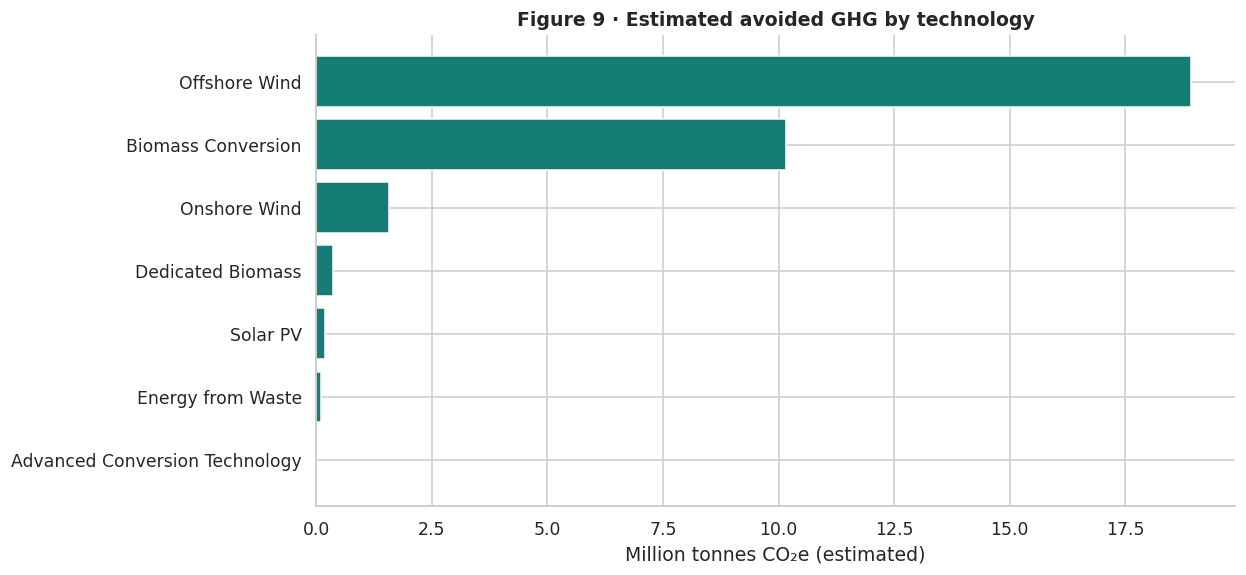

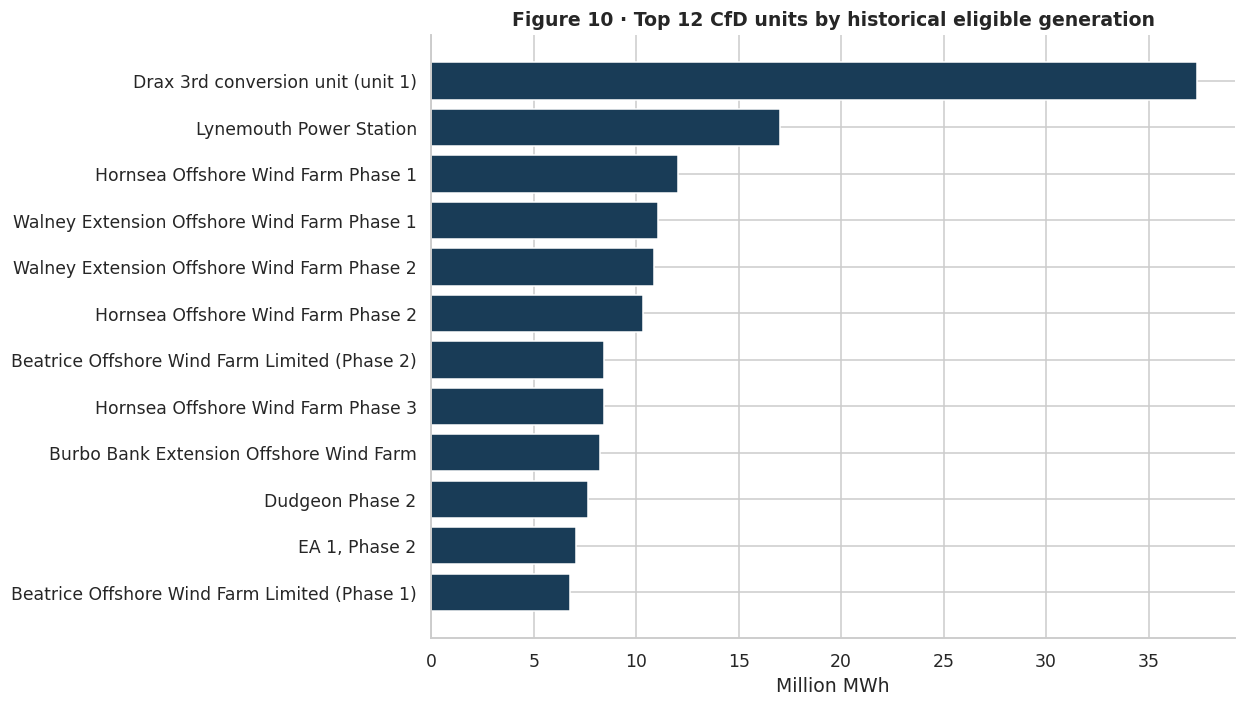

In [10]:
# Figure 9: avoided emissions by technology
fig, ax = plt.subplots()
co2 = tech_total.sort_values("Avoided_tCO2e")
ax.barh(co2["Technology"], co2["Avoided_tCO2e"] / 1e6, color=COLORS["teal"])
ax.set(title="Figure 9 · Estimated avoided GHG by technology", xlabel="Million tonnes CO₂e (estimated)", ylabel="")
plt.tight_layout(); plt.show()

# Figure 10: project-level contribution
projects = actual.groupby(["CfD_ID", "Name_of_CfD_Unit", "Technology"], as_index=False).agg(
    Generation_MWh=("CFD_Generation_MWh", "sum"), Payments_GBP=("CFD_Payments_GBP", "sum"))
leaders = projects.nlargest(12, "Generation_MWh").sort_values("Generation_MWh")
fig, ax = plt.subplots(figsize=(11.5, 6.6))
ax.barh(leaders["Name_of_CfD_Unit"], leaders["Generation_MWh"] / 1e6, color=COLORS["navy"])
ax.set(title="Figure 10 · Top 12 CfD units by historical eligible generation", xlabel="Million MWh", ylabel="")
plt.tight_layout(); plt.show()

## 5. Contract portfolio snapshot

The portfolio file is a **current-status snapshot**, not a historic time series. Contract capacity (MW) is not the same as annual energy generation (MWh). I do not use expected start dates to imply that a unit actually began generating on that date.

Total contract capacity in snapshot (all statuses): 55,479 MW


,Technology_Type,Capacity_MW,Contracts
7,Offshore Wind,"31,346.93",81
10,Solar PV,"12,011.07",368
8,Onshore Wind,"5,258.75",98
6,Nuclear,"3,287.16",1
9,Remote Island Wind,"1,096.42",11
1,Biomass Conversion,"1,051.79",2
4,Floating Offshore Wind,624.50,5
2,Dedicated Biomass,373.16,3
0,Advanced Conversion Technology,149.31,10
11,Tidal Stream,142.76,25


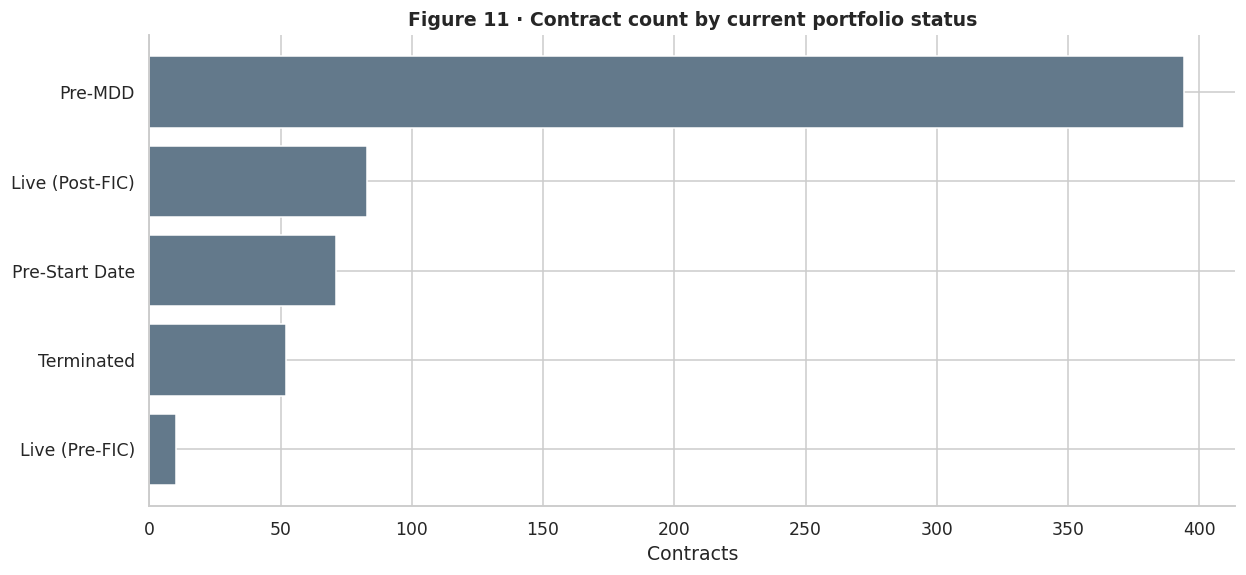

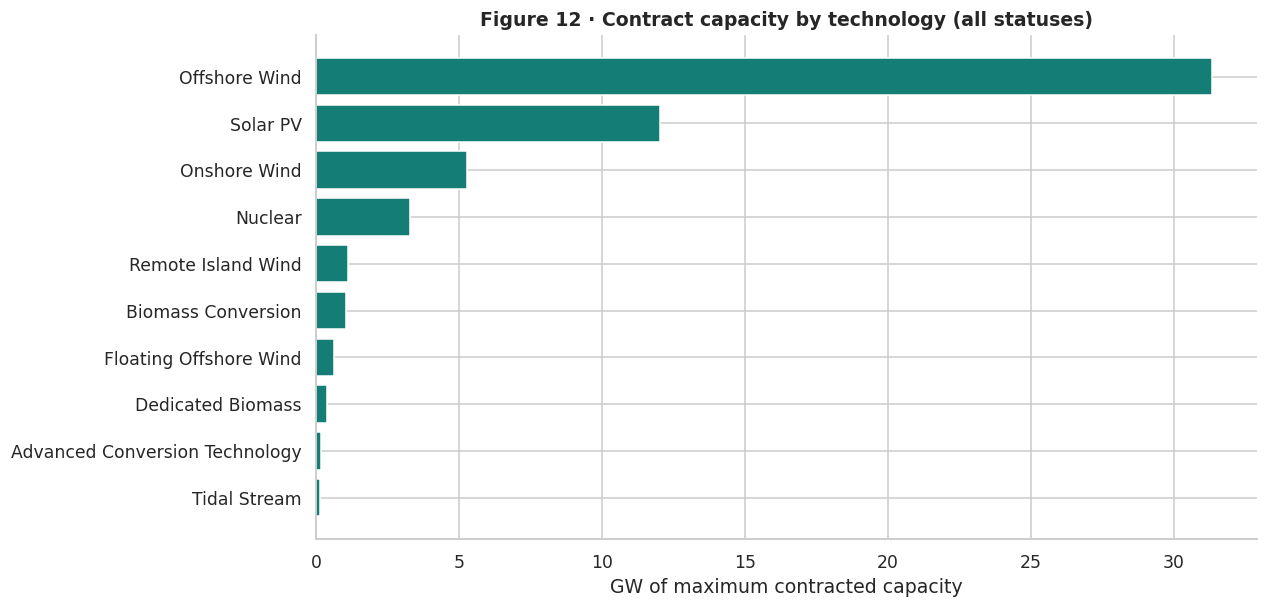

In [11]:
status_counts = portfolio["Status"].value_counts()
cap_by_tech = portfolio.groupby("Technology_Type", as_index=False).agg(
    Capacity_MW=("Maximum_Contract_Capacity_MW", "sum"), Contracts=("CFD_ID", "nunique")).sort_values("Capacity_MW", ascending=False)
print("Total contract capacity in snapshot (all statuses):", f"{portfolio['Maximum_Contract_Capacity_MW'].sum():,.0f} MW")
display(cap_by_tech.head(10))

# Figure 11: contract status
fig, ax = plt.subplots()
ax.barh(status_counts.index[::-1], status_counts.values[::-1], color=COLORS["slate"])
ax.set(title="Figure 11 · Contract count by current portfolio status", xlabel="Contracts", ylabel="")
plt.tight_layout(); plt.show()

# Figure 12: snapshot contract capacity
fig, ax = plt.subplots(figsize=(11.7, 5.7))
cut = cap_by_tech.head(10).sort_values("Capacity_MW")
ax.barh(cut["Technology_Type"], cut["Capacity_MW"] / 1000, color=COLORS["teal"])
ax.set(title="Figure 12 · Contract capacity by technology (all statuses)", xlabel="GW of maximum contracted capacity", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** the capacity chart includes terminated and pre-start contracts because its purpose is to describe the entire published portfolio. For a chart of *currently live* capacity, filter `Status` to the live categories. Summing the full snapshot and labelling it operational generation capacity would overstate what is producing electricity today.

## 6. Auction awards and strike prices

Auction awards provide another view of investment activity. The dataset contains projects across allocation rounds, with strike prices quoted in their published basis. For an inflation-adjusted comparison, a separate price-base conversion would be required; the raw strike prices are **not** automatically comparable in real terms.

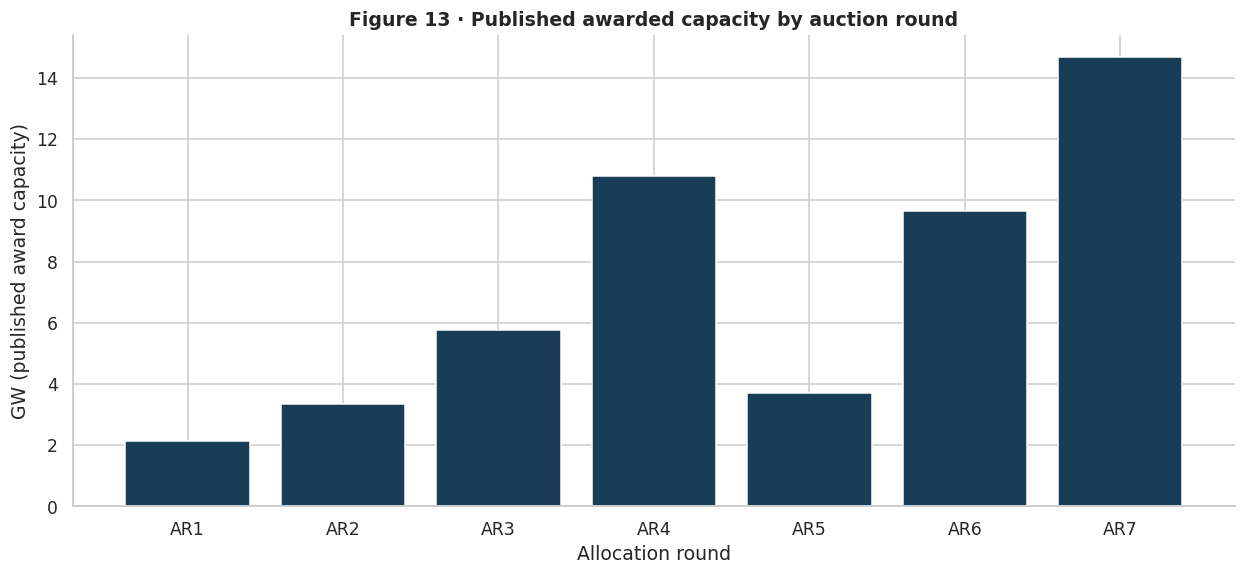

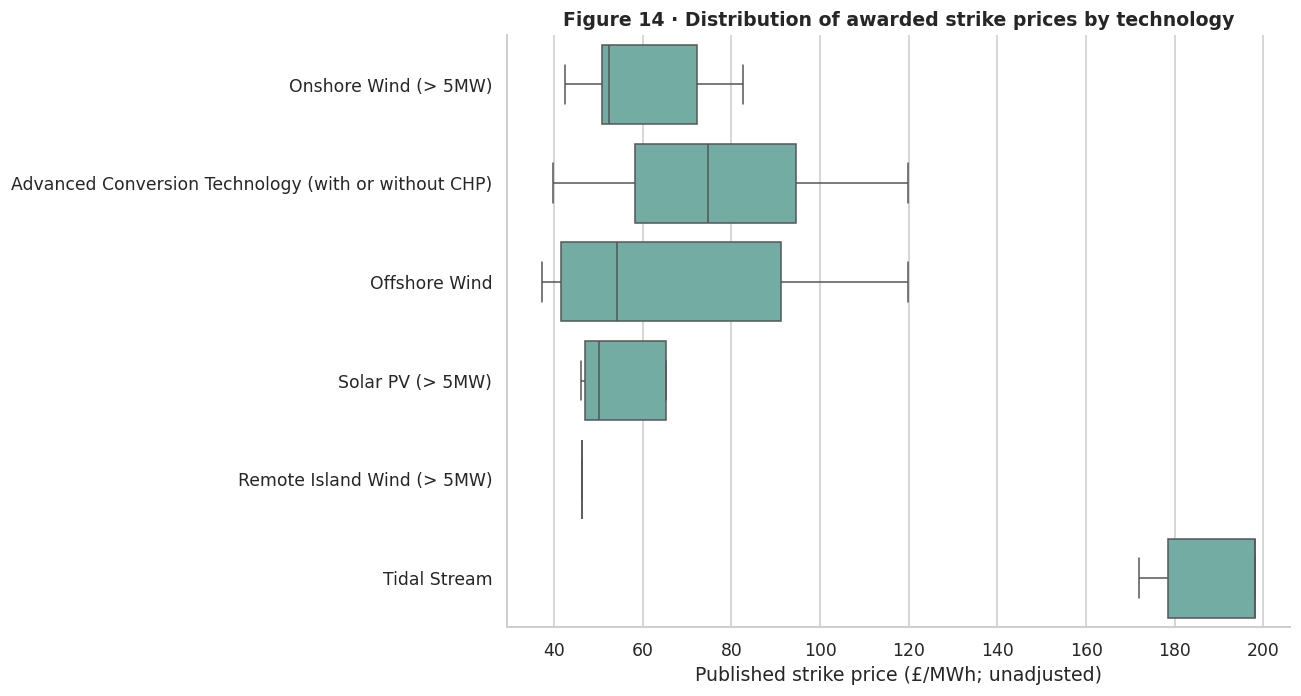

In [12]:
auction_rounds = auctions.groupby("Auction", as_index=False).agg(Capacity_MW=("Capacity_MW", "sum"), Awards=("Project_Name", "size"))
auction_rounds["Round_no"] = pd.to_numeric(auction_rounds["Auction"].str.extract(r"(\d+)")[0], errors="coerce")
auction_rounds = auction_rounds.sort_values("Round_no")

# Figure 13: awarded capacity by allocation round
fig, ax = plt.subplots()
ax.bar(auction_rounds["Auction"], auction_rounds["Capacity_MW"] / 1000, color=COLORS["navy"])
ax.set(title="Figure 13 · Published awarded capacity by auction round", ylabel="GW (published award capacity)", xlabel="Allocation round")
plt.tight_layout(); plt.show()

# Figure 14: auction strike prices for leading awarded technologies
frequent = auctions["Technology_Type"].value_counts().head(6).index.tolist()
auction_plot = auctions[auctions["Technology_Type"].isin(frequent)]
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.boxplot(data=auction_plot, x="Strike_Price_GBP_Per_MWh", y="Technology_Type", color="#6AB5A9", showfliers=False, ax=ax)
ax.set(title="Figure 14 · Distribution of awarded strike prices by technology", xlabel="Published strike price (£/MWh; unadjusted)", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** awarded capacity is not an estimate of installed or operational capacity. Some projects may be delayed, withdrawn, terminated or not yet live. Similarly, these strike-price distributions mix awards from different years and price bases, so they show the published spread rather than technology cost improvements on a like-for-like real-terms basis.

## 7. Financial-year strike-price and market-price forecasts

The financial-year table includes technology/connection-level **weighted-average strike prices** and DESNZ forecast wholesale prices. A weighted average cannot safely be summed across rows. I keep the rows at their original technology-by-connection grain and use medians for an illustrative cross-row chart, rather than claiming to calculate a portfolio-wide weighted average without the underlying capacity weights.

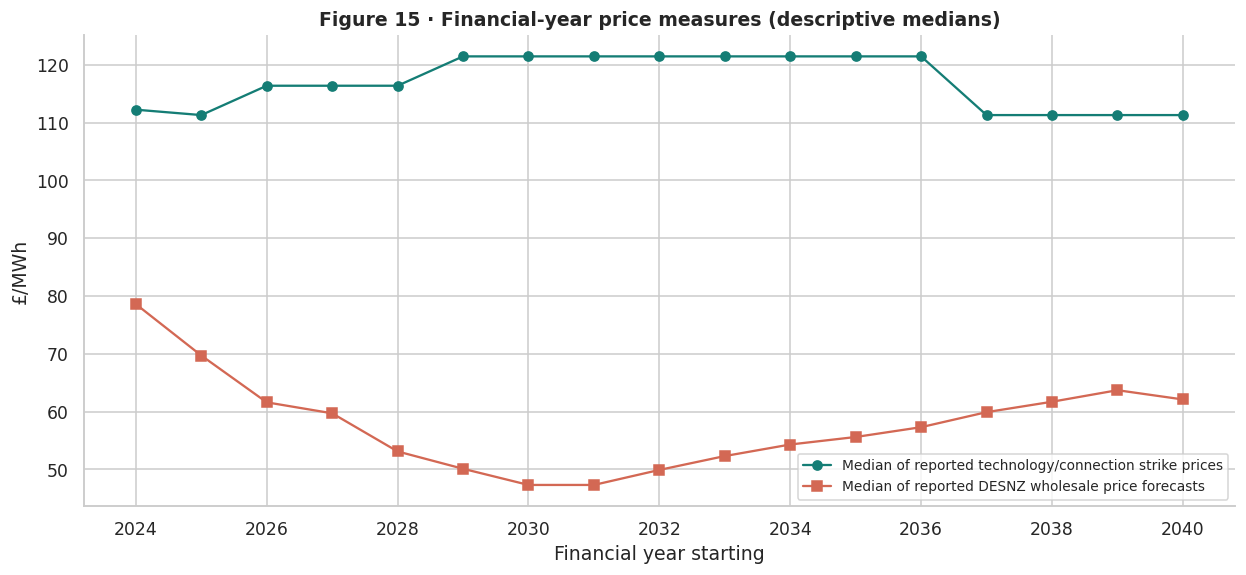

In [13]:
annual["Start_Year"] = pd.to_numeric(annual["Financial_Year"].str[:4], errors="coerce")
annual_valid = annual.dropna(subset=["Weighted_Average_Strike_Price_GBP_per_MWh", "Start_Year"]).copy()
annual_median = annual_valid.groupby("Start_Year", as_index=False).agg(
    Median_Strike=("Weighted_Average_Strike_Price_GBP_per_MWh", "median"),
    Median_Forecast_Wholesale=("DESNZ_Forecast_Wholesale_Price_GBP_per_MWh", "median"))

# Figure 15: forecast median price levels
fig, ax = plt.subplots()
ax.plot(annual_median["Start_Year"], annual_median["Median_Strike"], marker="o", color=COLORS["teal"], label="Median of reported technology/connection strike prices")
ax.plot(annual_median["Start_Year"], annual_median["Median_Forecast_Wholesale"], marker="s", color=COLORS["coral"], label="Median of reported DESNZ wholesale price forecasts")
ax.set(title="Figure 15 · Financial-year price measures (descriptive medians)", xlabel="Financial year starting", ylabel="£/MWh")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 8. Forward reference-price forecasts

This source contains forecasts identified by a quarterly obligation/determination label and technology. I retain that **forecast window label** instead of taking a naive average of repeated dates from different determinations. The plot below uses a selected determination window, not a historical observed market-price series.

Available determination windows:


,Quarterly_Obligation_Period,Records,Start,End
0,Determination 01/01/2027-31/03/2027,810,2027-01-01,2027-03-31
1,Determination 01/07/2026-30/09/2026,644,2026-07-01,2026-09-30
2,Determination 01/10/2026-31/12/2026,736,2026-10-01,2026-12-31
3,In Period Adjustment 17/08/2026-30/09/2026,315,2026-08-17,2026-09-30


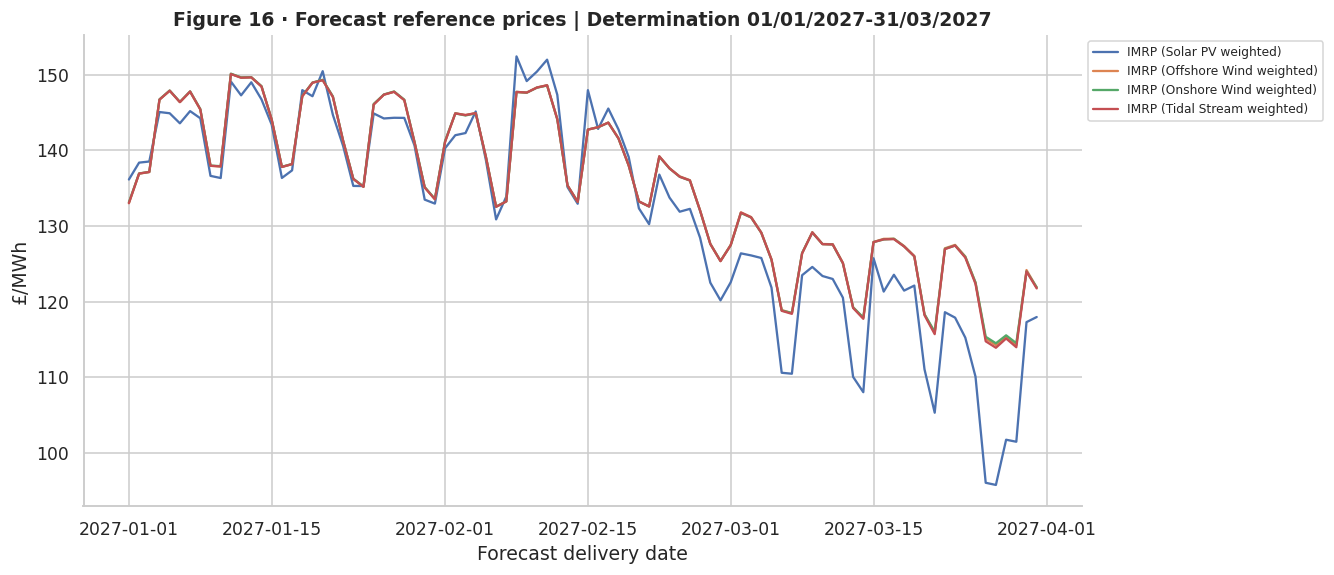

In [14]:
print("Available determination windows:")
display(market.groupby("Quarterly_Obligation_Period", as_index=False).agg(
    Records=("Technology", "size"), Start=("DateTime", "min"), End=("DateTime", "max")))
# Choose the most populated window for a legible comparison.
window = market["Quarterly_Obligation_Period"].value_counts().index[0]
market_one = market[market["Quarterly_Obligation_Period"] == window]
labels = market_one["Technology"].value_counts().head(4).index

# Figure 16: forecast reference prices by technology within one determination window
fig, ax = plt.subplots(figsize=(12.3, 5.4))
for tech in labels:
    series = market_one[market_one["Technology"] == tech].sort_values("DateTime")
    ax.plot(series["DateTime"], series["Forecast_Reference_Price_GBP_per_MWh"], linewidth=1.5, label=tech.replace("Forecast ", ""))
ax.set(title="Figure 16 · Forecast reference prices | " + window[:48], xlabel="Forecast delivery date", ylabel="£/MWh")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

## 9. In-period tracking: revisions to payment forecasts

The dataset has future-looking daily rows and some initial forecasts are missing. The **actual CfD payment column is entirely empty**, so it would be incorrect to calculate forecast accuracy, MAPE or forecast bias against observed actuals. Instead, I compare the initial and latest forecasts **only on dates where both exist**. A revision is not a forecast error.

Comparable dates with both forecasts: 182
Median absolute forecast revision: £1,971,298


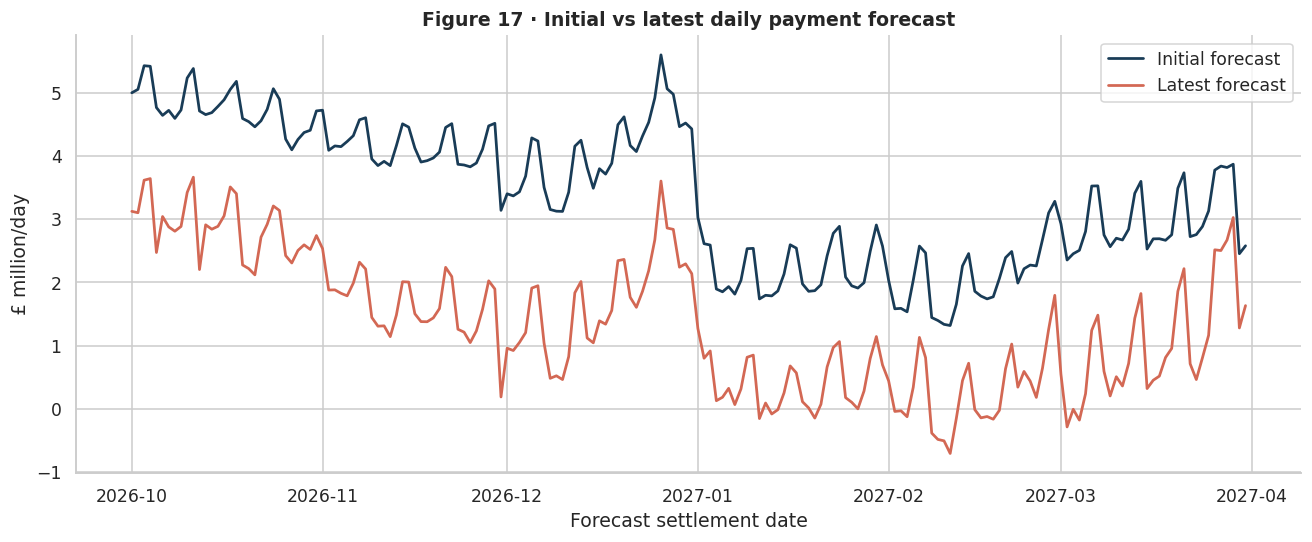

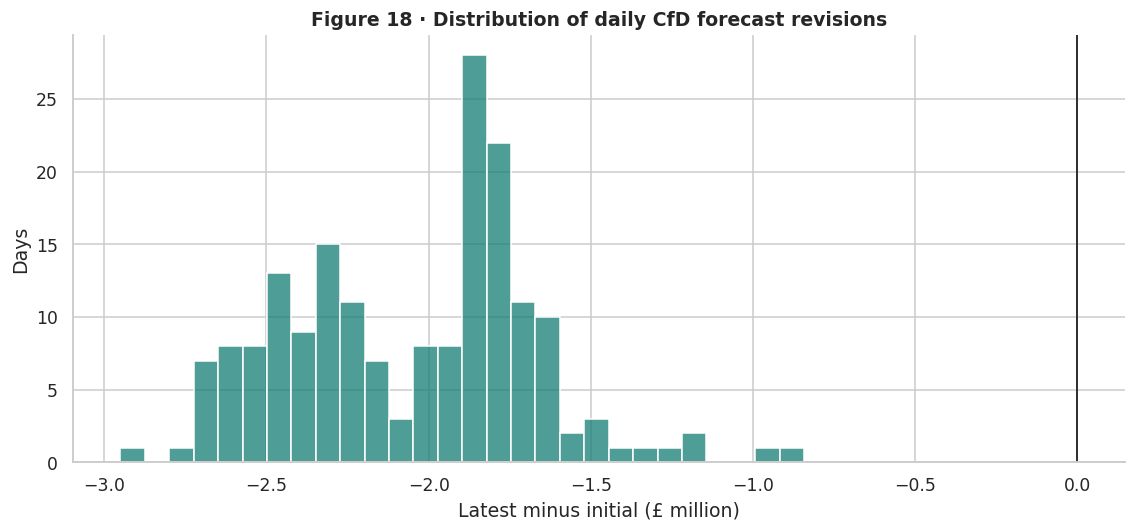

In [15]:
forecast_compare = tracking.dropna(subset=["Initial_Forecast_CFD_Payments_GBP", "Latest_Forecast_CFD_Payments_GBP"]).sort_values("Settlement_Date").copy()
forecast_compare["Revision_GBP"] = forecast_compare["Latest_Forecast_CFD_Payments_GBP"] - forecast_compare["Initial_Forecast_CFD_Payments_GBP"]
forecast_compare["Revision_Pct"] = np.where(
    forecast_compare["Initial_Forecast_CFD_Payments_GBP"].abs() > 0,
    100 * forecast_compare["Revision_GBP"] / forecast_compare["Initial_Forecast_CFD_Payments_GBP"].abs(), np.nan)
print("Comparable dates with both forecasts:", len(forecast_compare))
print("Median absolute forecast revision:", f"£{forecast_compare['Revision_GBP'].abs().median():,.0f}" if len(forecast_compare) else "n/a")

# Figure 17: initial versus latest forecast, comparable dates only
fig, ax = plt.subplots(figsize=(12.1, 5.1))
ax.plot(forecast_compare["Settlement_Date"], forecast_compare["Initial_Forecast_CFD_Payments_GBP"] / 1e6,
        label="Initial forecast", linewidth=1.8, color=COLORS["navy"])
ax.plot(forecast_compare["Settlement_Date"], forecast_compare["Latest_Forecast_CFD_Payments_GBP"] / 1e6,
        label="Latest forecast", linewidth=1.8, color=COLORS["coral"])
ax.set(title="Figure 17 · Initial vs latest daily payment forecast", xlabel="Forecast settlement date", ylabel="£ million/day")
ax.legend(); plt.tight_layout(); plt.show()

# Figure 18: revision distribution
fig, ax = plt.subplots(figsize=(10.5, 5.0))
sns.histplot(forecast_compare["Revision_GBP"] / 1e6, bins=28, color=COLORS["teal"], edgecolor="white", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Figure 18 · Distribution of daily CfD forecast revisions", xlabel="Latest minus initial (£ million)", ylabel="Days")
plt.tight_layout(); plt.show()

**Interpretation:** forecast revisions can reveal how expectations change between releases, but not how accurate those expectations were. Some days are absent from the initial forecasts; the paired-date filter is necessary to avoid creating revisions where no initial baseline exists.

## 10. Prepare a single Tableau-ready dataset

### Why the export uses a long format

The six files have different grains and dates. A wide join would repeat the same values across unrelated auction awards, contracts and forecast observations. Instead, I export **one long-format fact table** with a `record_group` and `metric` column. Each row means one measure for one explicitly identified observation or reporting period.

This lets Tableau build dashboards from a single CSV while preserving important distinctions:

- **Historical unit-month** → historical generation, payments, avoided emissions and price-weighted numerators.
- **Portfolio contract snapshot** → one contract per record; no invented snapshot or operational date.
- **Auction award** → one published award, preserving the original auction name.
- **Financial-year benchmark** → non-additive price averages, split by technology and connection.
- **Forecast reference price day** → forward price forecasts, preserving their determination window.
- **Payment forecast day** → initial and latest forecast values, not actual outcomes.

**Tableau rule:** filter `record_group` and `metric` before charting. For quantities marked `SUM` in `aggregation_hint`, SUM is appropriate within their record group. For prices marked `AVG`, use AVG only over a carefully defined comparison group. Weighted historic price series can be rebuilt from the exported numerator fields and generation totals.

In [16]:
# The shared layout makes a multi-source Tableau workbook possible from one CSV.
FIELDS = ["record_group", "grain", "date", "year", "month", "technology", "project", "cfd_id",
          "allocation_round", "status", "auction", "region", "connection", "financial_year",
          "forecast_window", "reference_type", "metric", "value", "unit", "aggregation_hint", "source_file"]
rows = []

def add_metrics(source, group, grain, measures, dimensions, date_field=None):
    """Append selected numeric measures to the common long format; no unsupported joins."""
    base = source.copy()
    d = pd.DataFrame(index=base.index)
    for dest, src in dimensions.items():
        d[dest] = base[src] if src in base else pd.NA
    d["date"] = pd.to_datetime(base[date_field], errors="coerce") if date_field else pd.NaT
    d["record_group"] = group
    d["grain"] = grain
    d["source_file"] = FILES[measures[0][4]]
    for src, label, unit, hint, file_key in measures:
        if src not in base.columns:
            continue
        part = d.copy()
        part["metric"] = label
        part["value"] = pd.to_numeric(base[src], errors="coerce")
        part["unit"] = unit
        part["aggregation_hint"] = hint
        part = part.dropna(subset=["value"])
        rows.append(part)

# Aggregate to unit/month; contract and technology dimensions are stable within unit in this source.
keys = ["Month", "CfD_ID", "Name_of_CfD_Unit", "Technology", "Allocation_round", "Reference_Type"]
historic_month = actual.groupby(keys, as_index=False).agg(
    Generation_MWh=("CFD_Generation_MWh", "sum"),
    Payments_GBP=("CFD_Payments_GBP", "sum"),
    Avoided_tCO2e=("Avoided_GHG_tonnes_CO2e", "sum"),
    Avoided_GHG_Cost_GBP=("Avoided_GHG_Cost_GBP", "sum"),
    Weighted_Strike_Numerator=("Generation_x_Strike", "sum"),
    Weighted_Market_Numerator=("Generation_x_Market", "sum"))
historic_month["Payment_per_MWh"] = historic_month["Payments_GBP"] / historic_month["Generation_MWh"].replace(0, np.nan)
historic_month["GHG_per_MWh"] = historic_month["Avoided_tCO2e"] / historic_month["Generation_MWh"].replace(0, np.nan)
historic_month["Strike_weighted"] = historic_month["Weighted_Strike_Numerator"] / historic_month["Generation_MWh"].replace(0, np.nan)
historic_month["Market_weighted"] = historic_month["Weighted_Market_Numerator"] / historic_month["Generation_MWh"].replace(0, np.nan)

add_metrics(historic_month, "Historical unit-month", "CfD unit x month x reference type", [
    ("Generation_MWh", "CfD generation", "MWh", "SUM", "actual"),
    ("Payments_GBP", "Net CfD payments", "GBP", "SUM", "actual"),
    ("Avoided_tCO2e", "Estimated avoided GHG", "tonnes CO2e", "SUM", "actual"),
    ("Avoided_GHG_Cost_GBP", "Reported avoided GHG cost", "GBP", "SUM", "actual"),
    ("Weighted_Strike_Numerator", "Generation x strike price", "GBP", "SUM", "actual"),
    ("Weighted_Market_Numerator", "Generation x reference price", "GBP", "SUM", "actual"),
    ("Strike_weighted", "Unit-month weighted strike price", "GBP/MWh", "AVG", "actual"),
    ("Market_weighted", "Unit-month weighted reference price", "GBP/MWh", "AVG", "actual"),
    ("Payment_per_MWh", "Unit-month net payment per MWh", "GBP/MWh", "AVG", "actual"),
    ("GHG_per_MWh", "Unit-month estimated GHG per MWh", "tonnes CO2e/MWh", "AVG", "actual"),
], {"technology":"Technology", "project":"Name_of_CfD_Unit", "cfd_id":"CfD_ID", "allocation_round":"Allocation_round", "reference_type":"Reference_Type"}, "Month")

add_metrics(portfolio, "Portfolio contract snapshot", "CfD contract, source snapshot undated", [
    ("Maximum_Contract_Capacity_MW", "Maximum contract capacity", "MW", "SUM", "portfolio"),
], {"technology":"Technology_Type", "project":"Name_of_CFD_Unit", "cfd_id":"CFD_ID", "allocation_round":"Allocation_Round", "status":"Status", "connection":"Transmission_or_Distribution_connection"})
# One count per contract, allowing contract counts by status without counting capacities.
portfolio_count = portfolio.assign(Contract_Count=1)
add_metrics(portfolio_count, "Portfolio contract snapshot", "CfD contract, source snapshot undated", [
    ("Contract_Count", "Contract count", "contracts", "SUM", "portfolio")
], {"technology":"Technology_Type", "project":"Name_of_CFD_Unit", "cfd_id":"CFD_ID", "allocation_round":"Allocation_Round", "status":"Status", "connection":"Transmission_or_Distribution_connection"})

auctions_export = auctions.assign(Award_Count=1)
add_metrics(auctions_export, "Auction award", "Published project award", [
    ("Capacity_MW", "Awarded capacity", "MW", "SUM", "auctions"),
    ("Award_Count", "Award count", "awards", "SUM", "auctions"),
    ("Strike_Price_GBP_Per_MWh", "Award strike price", "GBP/MWh", "AVG", "auctions")
], {"technology":"Technology_Type", "project":"Project_Name", "auction":"Auction", "region":"Region"}, "Publication_Date")

add_metrics(annual, "Financial-year benchmark", "Technology x connection x financial year", [
    ("Weighted_Average_Strike_Price_GBP_per_MWh", "FY weighted average strike price", "GBP/MWh", "AVG", "annual_forecast"),
    ("DESNZ_Forecast_Wholesale_Price_GBP_per_MWh", "FY forecast wholesale price", "GBP/MWh", "AVG", "annual_forecast"),
], {"technology":"Technology_type", "connection":"Transmission_or_Distribution_connection", "financial_year":"Financial_Year"})

add_metrics(market, "Forecast reference price day", "Forecast date x technology x determination window", [
    ("Forecast_Reference_Price_GBP_per_MWh", "Forecast reference price", "GBP/MWh", "AVG", "market_forecast"),
], {"technology":"Technology", "forecast_window":"Quarterly_Obligation_Period"}, "DateTime")

tracking_export = tracking.copy()
tracking_export["Forecast_revision_GBP"] = tracking_export["Latest_Forecast_CFD_Payments_GBP"] - tracking_export["Initial_Forecast_CFD_Payments_GBP"]
add_metrics(tracking_export, "Payment forecast day", "Settlement date x payment forecast snapshot", [
    ("Initial_Forecast_CFD_Payments_GBP", "Initial forecast CfD payments", "GBP", "SUM", "tracking"),
    ("Latest_Forecast_CFD_Payments_GBP", "Latest forecast CfD payments", "GBP", "SUM", "tracking"),
    ("Forecast_revision_GBP", "CfD forecast revision", "GBP", "SUM", "tracking"),
    ("Initial_Forecast_Eligible_Demand_MWh", "Initial forecast eligible demand", "MWh", "SUM", "tracking"),
    ("Latest_Forecast_Eligible_Demand_MWh", "Latest forecast eligible demand", "MWh", "SUM", "tracking"),
    ("Initial_Forecast_Supplier_Payments_GBP", "Initial forecast supplier payments", "GBP", "SUM", "tracking"),
    ("Latest_Forecast_Supplier_Payments_GBP", "Latest forecast supplier payments", "GBP", "SUM", "tracking"),
    ("Latest_Forecast_LCDCFD_Payments_GBP", "Latest forecast LCDCfD payments", "GBP", "SUM", "tracking"),
], {}, "Settlement_Date")

tableau = pd.concat(rows, ignore_index=True, sort=False)
for col in FIELDS:
    if col not in tableau:
        tableau[col] = pd.NA
# Derive time fields from the actual date, leaving undated snapshots and financial-year measures undated.
tableau["date"] = pd.to_datetime(tableau["date"], errors="coerce")
tableau["year"] = tableau["date"].dt.year.astype("Int64")
tableau["month"] = tableau["date"].dt.strftime("%Y-%m")
tableau = tableau[FIELDS].sort_values(["record_group", "date", "technology", "project", "metric"], na_position="last").reset_index(drop=True)

output_file = OUT / "LCCC_CfD_Tableau_Consolidated.csv"
tableau.to_csv(output_file, index=False, date_format="%Y-%m-%d", float_format="%.6f")
print("Tableau file:", output_file)
print("Export rows:", f"{len(tableau):,}")
display(tableau.groupby(["record_group", "metric", "unit", "aggregation_hint"], dropna=False).size().reset_index(name="rows"))

Tableau file: /mnt/data/UK_CfD_Analytics_Project/data/processed/LCCC_CfD_Tableau_Consolidated.csv
Export rows: 47,361


,record_group,metric,unit,aggregation_hint,rows
0,Auction award,Award count,awards,SUM,570
1,Auction award,Award strike price,GBP/MWh,AVG,570
2,Auction award,Awarded capacity,MW,SUM,570
3,Financial-year benchmark,FY forecast wholesale price,GBP/MWh,AVG,323
4,Financial-year benchmark,FY weighted average strike price,GBP/MWh,AVG,265
5,Forecast reference price day,Forecast reference price,GBP/MWh,AVG,2505
6,Historical unit-month,CfD generation,MWh,SUM,3917
7,Historical unit-month,Estimated avoided GHG,tonnes CO2e,SUM,3917
8,Historical unit-month,Generation x reference price,GBP,SUM,3917
9,Historical unit-month,Generation x strike price,GBP,SUM,3917


## 11. Validate the export against the raw source

Before using the CSV in Tableau, the key historical totals should reconcile exactly to the source. I also check that auction capacity and the portfolio capacity match their respective downloaded files. These checks are particularly important because the export contains many metrics in a single `value` column.

In [17]:
def exported_sum(group, metric):
    return tableau.loc[(tableau["record_group"] == group) & (tableau["metric"] == metric), "value"].sum()

checks = pd.DataFrame([
    ["Historical generation (MWh)", actual["CFD_Generation_MWh"].sum(), exported_sum("Historical unit-month", "CfD generation")],
    ["Historical net payments (GBP)", actual["CFD_Payments_GBP"].sum(), exported_sum("Historical unit-month", "Net CfD payments")],
    ["Estimated avoided GHG (tCO2e)", actual["Avoided_GHG_tonnes_CO2e"].sum(), exported_sum("Historical unit-month", "Estimated avoided GHG")],
    ["Portfolio max capacity (MW)", portfolio["Maximum_Contract_Capacity_MW"].sum(), exported_sum("Portfolio contract snapshot", "Maximum contract capacity")],
    ["Auction award capacity (MW)", auctions["Capacity_MW"].sum(), exported_sum("Auction award", "Awarded capacity")],
], columns=["Check", "Raw CSV sum", "Tableau sum"])
checks["Difference"] = checks["Tableau sum"] - checks["Raw CSV sum"]
checks["Pass"] = np.isclose(checks["Raw CSV sum"], checks["Tableau sum"], rtol=1e-10, atol=.01)
display(checks)
assert checks["Pass"].all(), "The Tableau export did not reconcile with the source data"
assert tableau.loc[tableau["record_group"] == "Portfolio contract snapshot", "date"].isna().all(), "A portfolio snapshot date was invented"
assert not tableau.loc[tableau["record_group"] == "Payment forecast day", "metric"].str.startswith("Actual ").any(), "Nonexistent tracking actuals were exported"
print("Checks passed. Final CSV size:", round(output_file.stat().st_size / 1_048_576, 2), "MB")

,Check,Raw CSV sum,Tableau sum,Difference,Pass
0,Historical generation (MWh),"211,542,758.72","211,542,758.72",0.00,True
1,Historical net payments (GBP),"13,841,895,268.85","13,841,895,268.85",0.00,True
2,Estimated avoided GHG (tCO2e),"31,307,245.23","31,307,245.23",0.00,True
3,Portfolio max capacity (MW),"55,478.60","55,478.60",0.00,True
4,Auction award capacity (MW),"50,066.66","50,066.66",-0.00,True


Checks passed. Final CSV size: 11.54 MB


## 12. Building the Tableau dashboards

### Dashboard A — Historic Generation & Carbon
- Filter `record_group = Historical unit-month`.
- Use `metric = CfD generation` for an area chart by `month` and `technology` (SUM of `value`).
- Use `metric = Estimated avoided GHG` for an emissions time series and a technology comparison (SUM of `value`).
- Add project filters using `project` or `cfd_id`.

### Dashboard B — CfD Financial Flows
- Use `metric = Net CfD payments` within `Historical unit-month`. Keep the signed values.
- Create separate views for `Portfolio contract snapshot` (capacity by status) and `Auction award` (capacity by `auction` or strike-price distributions).
- **Generation-weighted reference price**, within historical unit-month only: use a calculated field with conditional aggregation:

```text
SUM(IF [metric] = "Generation x reference price" THEN [value] END)
/
SUM(IF [metric] = "CfD generation" THEN [value] END)
```

- For a **generation-weighted strike price**, replace `Generation x reference price` with `Generation x strike price`. These expressions only work when the view is filtered to `record_group = Historical unit-month`.

### Dashboard C — Contracts, Prices & Forecast Revisions
- For portfolio status, `record_group = Portfolio contract snapshot` and `metric = Contract count` or `Maximum contract capacity`.
- For the forecast payment line chart, `record_group = Payment forecast day`, with `metric` filtered to initial and latest forecasts. They are distinct forecast series, **not actual vs forecast**.
- For forecast reference prices, `record_group = Forecast reference price day`, filter one `forecast_window` at a time to avoid mixing determination periods.
- For forward FY prices, `record_group = Financial-year benchmark`. Use `AVG([value])` for defined technology/connection groups, **not SUM**.

**Important:** do not add unlike metrics (e.g., MWh + GBP). The `unit`, `record_group`, `grain`, and `aggregation_hint` columns are included to make the chart choices explicit.

### What I would improve next

A robust follow-up would be to add dated snapshot archives and actual tracking values as they become available. Those would support genuine forecast accuracy evaluation and portfolio change tracking. The present notebook focuses on defensible descriptive analysis from the six downloaded files.